In [12]:
from background.modules.exchange_upbit import ExChangeUpbit
from background.modules.exchange__calculator import ExChangeCalculator
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import os

import datetime

In [5]:
interval = "minute5"
count = 200
days = 93

In [7]:
upbit = ExChangeUpbit()
upbit.set_ticker("KRW-BTC")

True

In [8]:


end_dt = datetime.datetime.now()
start_dt = end_dt - datetime.timedelta(days=days)

dfs = []
to = end_dt
max_call = int((days * 24 * 12) / count) + 2

for _ in range(max_call):
    df = upbit.get_ohlcv(
        interval=interval,
        date=to.strftime("%Y-%m-%d %H:%M:%S"),
        count=count
    )

    if df is None or df.empty:
        break

    dfs.append(df)

    oldest_dt = df["datetime"].iloc[0]

    # 30일 이전이면 종료
    if oldest_dt <= start_dt:
        break

    # 다음 호출 기준점
    to = oldest_dt - datetime.timedelta(minutes=5)

df_combined = (
    pd.concat(dfs)
    .drop_duplicates(subset="datetime")
    .sort_values("datetime")
    .reset_index(drop=True)
)

In [9]:
df_combined.head()

,open,high,low,close,volume,value,datetime
0,136450000.0,136525000.0,136142000.0,136266000.0,7.134473,9.723598e+08,2025-11-19 17:05:00
1,136250000.0,136299000.0,136139000.0,136200000.0,5.225341,7.117400e+08,2025-11-19 17:10:00
2,136200000.0,136230000.0,136033000.0,136033000.0,4.930139,6.712548e+08,2025-11-19 17:15:00
3,136093000.0,136182000.0,135892000.0,136161000.0,8.379371,1.139821e+09,2025-11-19 17:20:00
4,136161000.0,136551000.0,136132000.0,136502000.0,7.761069,1.058756e+09,2025-11-19 17:25:00


In [19]:
def apply_all_features(calculator):
    methods = [
        getattr(calculator, m)
        for m in dir(calculator)
        if callable(getattr(calculator, m))
        and m.startswith("set_")
        and m not in ["set_ohlcv"]
    ]
    
    for method in methods:
        try:
            method()
        except Exception:
            pass

    return calculator.get_df()

calculator = ExChangeCalculator(df_combined)
new_df = apply_all_features(calculator)
new_df.head(100)

In [20]:
def create_target(df, horizon=12):  # 예: minute5 기준 12 = 1시간
    df = df.copy()
    df["future_close"] = df["close"].shift(-horizon)
    df["return"] = (df["future_close"] - df["close"]) / df["close"]

    df["target"] = 0
    df.loc[df["return"] >= 0.005, "target"] = 1
    df.loc[df["return"] <= -0.005, "target"] = -1

    #df = df.dropna()
    return df

new_df2 = create_target(new_df, 15)
new_df2.head(100)

,open,high,low,close,volume,value,datetime,band_mid,stddev,band_upper,...,cum_volume,cum_vwap,vwap,weekday,weekday_cos,weekday_sin,wick_ratio,future_close,return,target
0,136450000.0,136525000.0,136142000.0,136266000.0,7.134473,9.723598e+08,2025-11-19 17:05:00,NaN,NaN,NaN,...,7.134473,9.725071e+08,1.363110e+08,2,-0.222521,0.974928,0.519582,135308000.0,-0.007030,-1
1,136250000.0,136299000.0,136139000.0,136200000.0,5.225341,7.117400e+08,2025-11-19 17:10:00,NaN,NaN,NaN,...,12.359814,1.684265e+09,1.362694e+08,2,-0.222521,0.974928,0.687500,135559000.0,-0.004706,0
2,136200000.0,136230000.0,136033000.0,136033000.0,4.930139,6.712548e+08,2025-11-19 17:15:00,NaN,NaN,NaN,...,17.289953,2.355250e+09,1.362207e+08,2,-0.222521,0.974928,0.152284,135762000.0,-0.001992,0
3,136093000.0,136182000.0,135892000.0,136161000.0,8.379371,1.139821e+09,2025-11-19 17:20:00,NaN,NaN,NaN,...,25.669324,3.495501e+09,1.361743e+08,2,-0.222521,0.974928,0.765517,135821000.0,-0.002497,0
4,136161000.0,136551000.0,136132000.0,136502000.0,7.761069,1.058756e+09,2025-11-19 17:25:00,NaN,NaN,NaN,...,33.430393,4.554072e+09,1.362255e+08,2,-0.222521,0.974928,0.186158,135959000.0,-0.003978,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,134096000.0,134607000.0,134064000.0,134281000.0,13.316245,1.789384e+09,2025-11-20 01:00:00,135870750.0,9.698198e+05,1.378104e+08,...,711.267618,9.664353e+10,1.358751e+08,3,-0.900969,0.433884,0.659300,133537000.0,-0.005541,-1
96,134281000.0,134562000.0,134084000.0,134345000.0,16.590464,2.228618e+09,2025-11-20 01:05:00,135808000.0,1.027166e+06,1.378623e+08,...,727.858081,9.887213e+10,1.358399e+08,3,-0.900969,0.433884,0.866109,133736000.0,-0.004533,0
97,134328000.0,134451000.0,134141000.0,134425000.0,9.024100,1.211934e+09,2025-11-20 01:10:00,135724600.0,1.069645e+06,1.378639e+08,...,736.882181,1.000844e+11,1.358215e+08,3,-0.900969,0.433884,0.687097,133680000.0,-0.005542,-1
98,134425000.0,134482000.0,133770000.0,133800000.0,34.105468,4.571594e+09,2025-11-20 01:15:00,135600650.0,1.143129e+06,1.378869e+08,...,770.987649,1.046551e+11,1.357417e+08,3,-0.900969,0.433884,0.122191,133140000.0,-0.004933,0


In [27]:
def run_feature_importance(upbit_module, interval="minute5"):

    results = {}

    for name, count in periods.items():

        print(f"processing {name} ...")

        df = upbit_module.get_ohlcv(interval=interval, count=count)

        calculator = ExChangeCalculator(df)
        df = apply_all_features(calculator)

        df = create_target(df, horizon=12)  # 1시간 후 기준

        importance = get_feature_importance(df)

        results[name] = importance

    return results



In [35]:
from background.modules.exchange_upbit import ExChangeUpbit
from background.modules.exchange__calculator import ExChangeCalculator

from sklearn.ensemble import RandomForestClassifier

import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
import os

import seaborn as sns

import datetime

In [36]:

def apply_all_features(calculator):
    methods = [
        getattr(calculator, m)
        for m in dir(calculator)
        if callable(getattr(calculator, m))
        and m.startswith("set_")
        and m not in ["set_ohlcv"]
    ]
    
    for method in methods:
        try:
            method()
        except Exception:
            pass

    return calculator.get_df()

def create_target(df, horizon=12):  # 예: minute5 기준 12 = 1시간
    df = df.copy()
    df["future_close"] = df["close"].shift(-horizon)
    df["return"] = (df["future_close"] - df["close"]) / df["close"]

    df["target"] = 0
    df.loc[df["return"] >= 0.005, "target"] = 1
    df.loc[df["return"] <= -0.005, "target"] = -1

    #df = df.dropna()
    return df

def cut_by_days(end_dt, df, days):
    start = end_dt - datetime.timedelta(days=days)
    return df[df["datetime"] >= start].copy()

def get_feature_importance(df):

    df = df.copy()

    X = df.drop(columns=["datetime", "target", "future_close", "return"], errors="ignore")
    y = df["target"]

    X = X.select_dtypes(include=[np.number])
    X = X.replace([np.inf, -np.inf], np.nan)
    X = X.fillna(0)

    valid_idx = X.index.intersection(y.index)
    X = X.loc[valid_idx]
    y = y.loc[valid_idx]

    if len(y.unique()) < 2:
        print("⚠ target class 부족")
        return None

    model = RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )

    model.fit(X, y)

    importance = pd.DataFrame({
        "feature": X.columns,
        "importance": model.feature_importances_
    }).sort_values(by="importance", ascending=False)

    return importance.head(30)

def plot_importance_pretty(importance_df, title="Feature Importance"):

    plt.figure(figsize=(10, 8))
    sns.barplot(
        x="importance",
        y="feature",
        data=importance_df,
        orient="h"
    )
    
    plt.title(title)
    plt.tight_layout()
    plt.show()

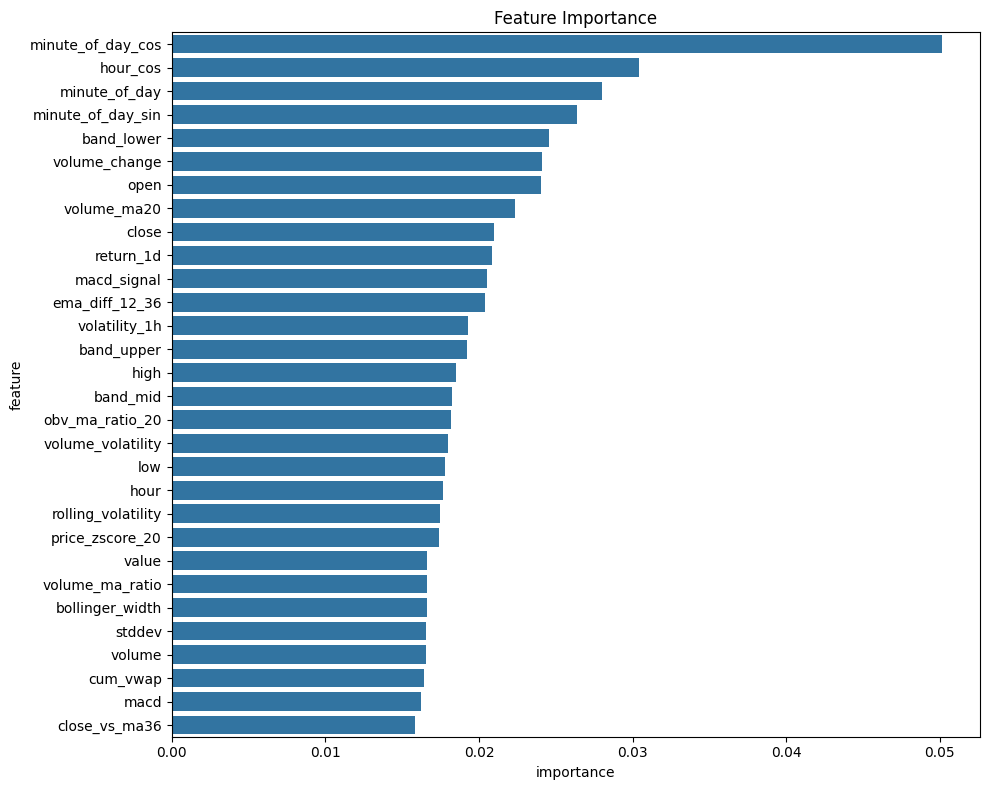

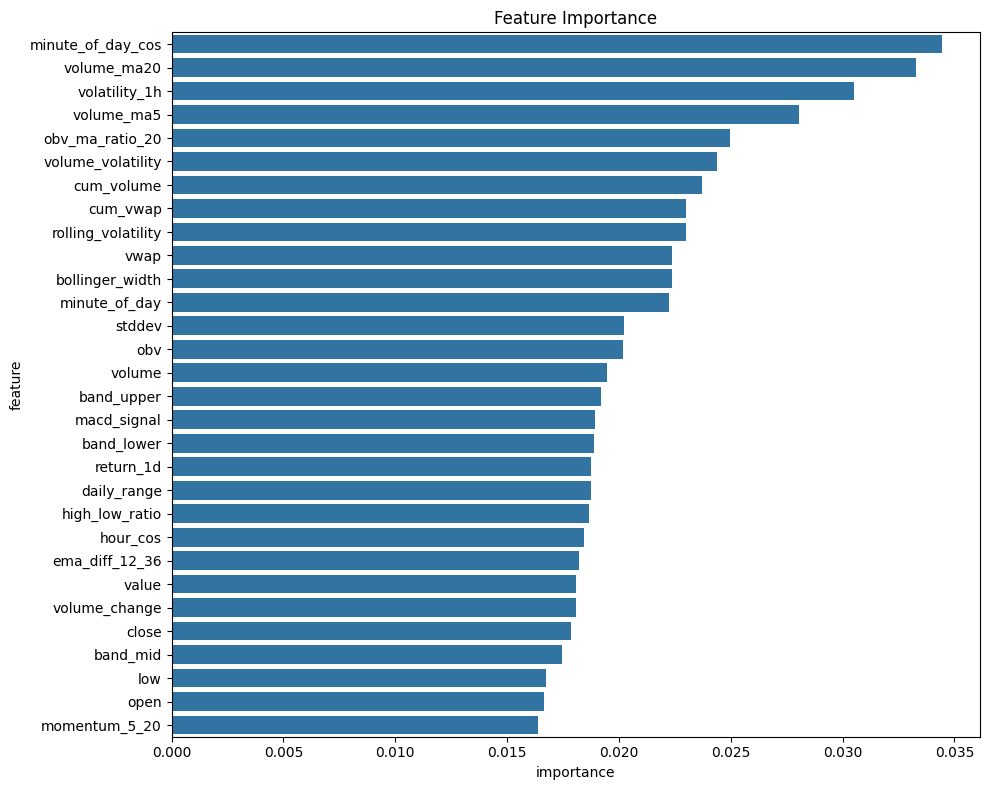

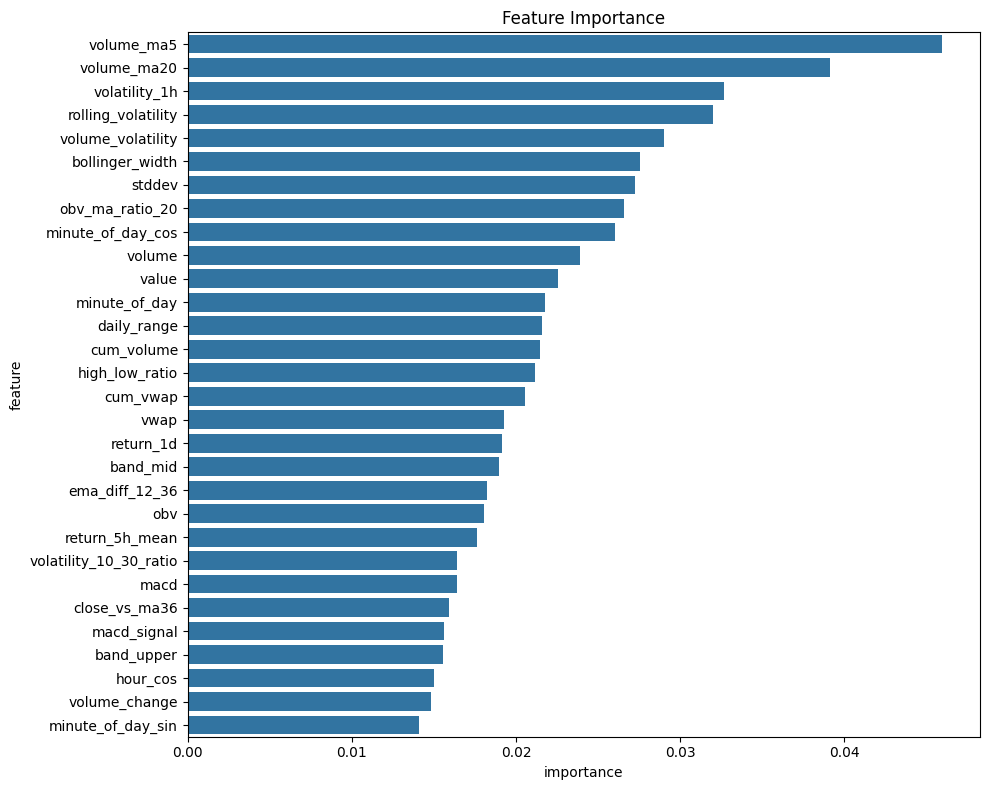

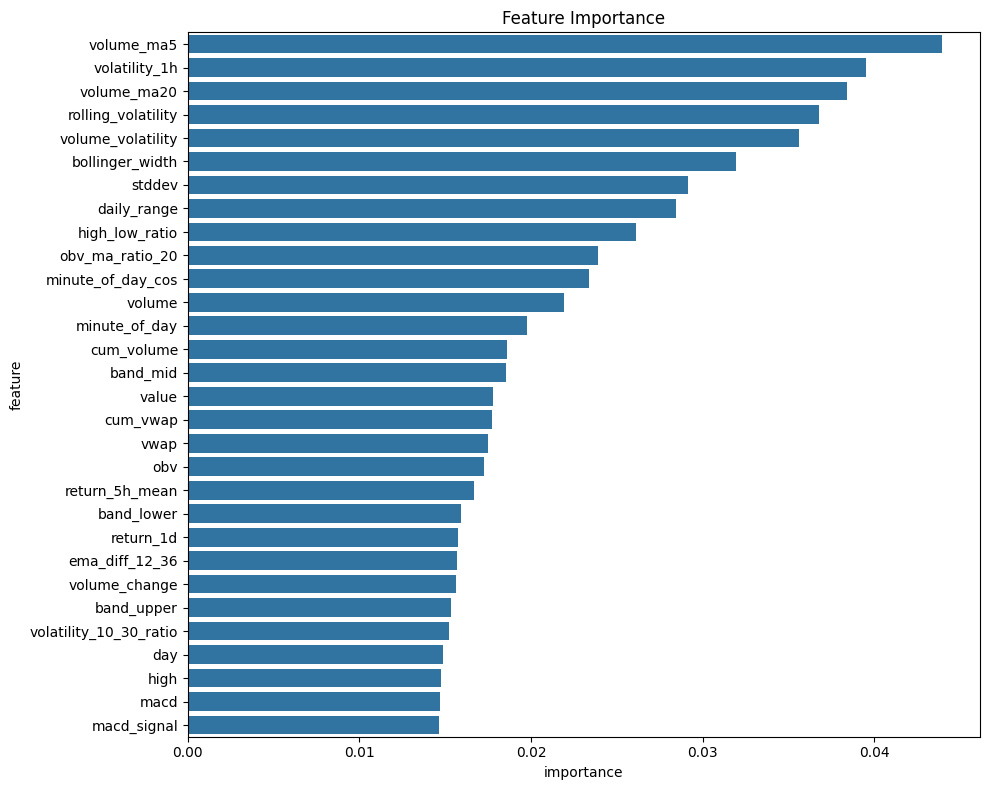

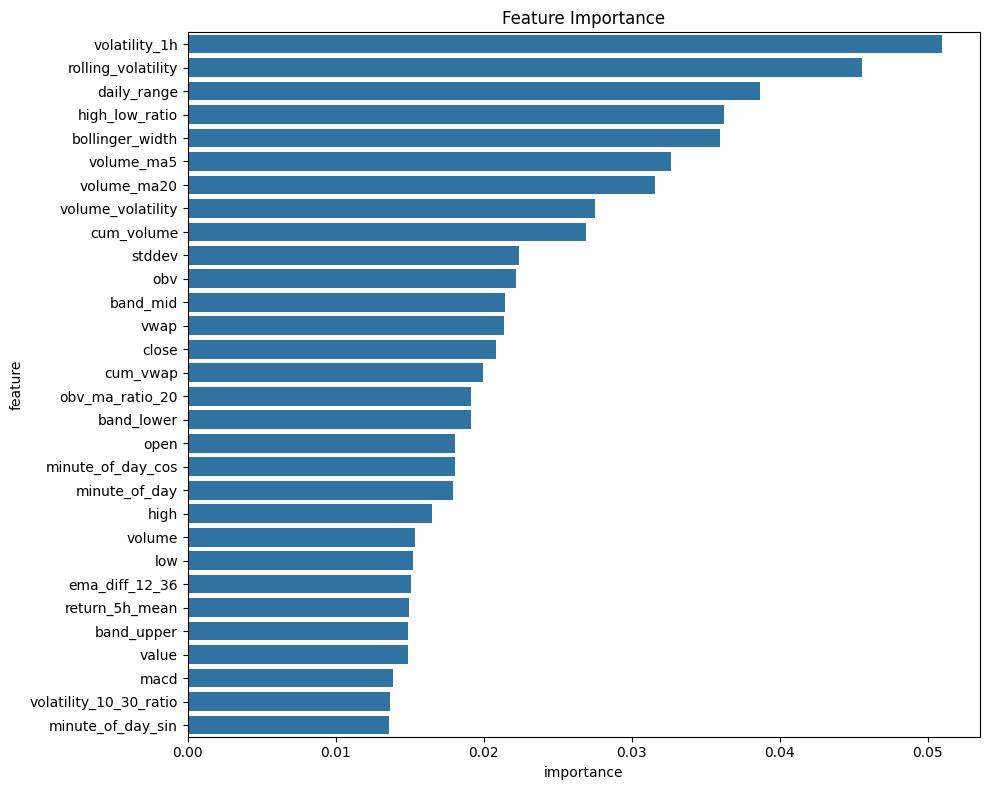

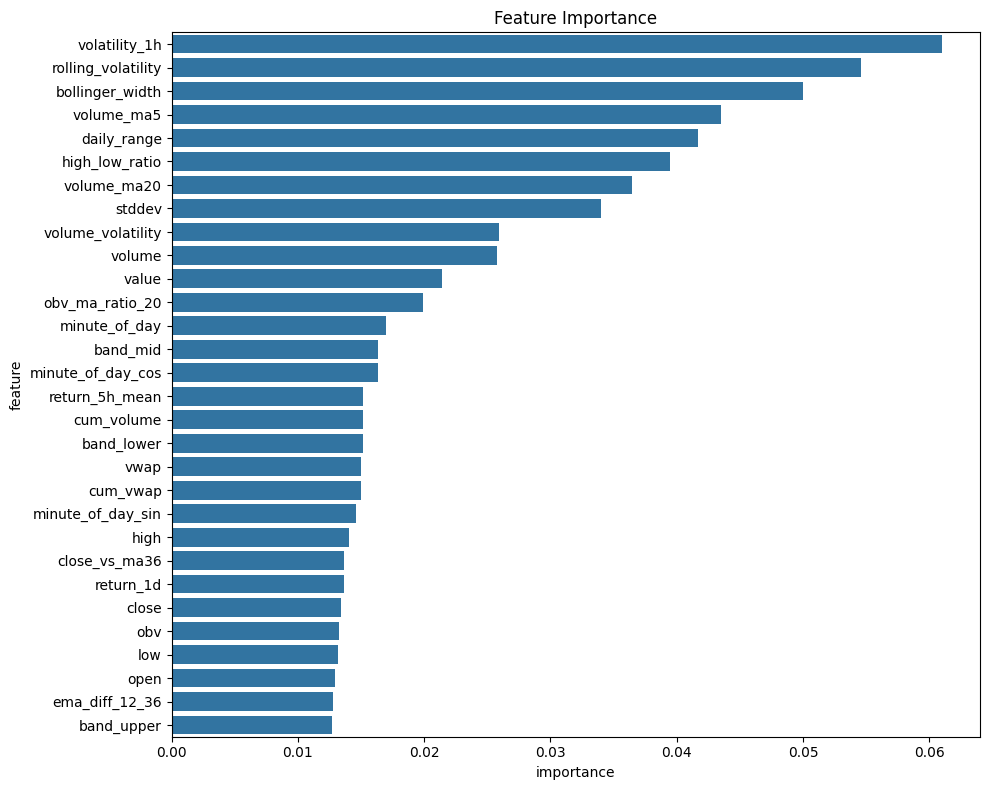

In [40]:

interval = "minute5"
count = 200
days = 93

DAY_COUNT = 288

periods = {
    "3_month": DAY_COUNT * 90,
    "2_month": DAY_COUNT * 60,
    "1_month": DAY_COUNT * 30,
    "3_week":  DAY_COUNT * 21,
    "2_week":  DAY_COUNT * 14,
    "1_week":  DAY_COUNT * 7,
}

upbit = ExChangeUpbit()
upbit.set_ticker("KRW-BTC")

end_dt = datetime.datetime.now()
start_dt = end_dt - datetime.timedelta(days=days)

dfs = []
to = end_dt
max_call = int((days * 24 * 12) / count) + 2

for _ in range(max_call):
    df = upbit.get_ohlcv(
        interval=interval,
        date=to.strftime("%Y-%m-%d %H:%M:%S"),
        count=count
    )

    if df is None or df.empty:
        break

    dfs.append(df)

    oldest_dt = df["datetime"].iloc[0]

    # 30일 이전이면 종료
    if oldest_dt <= start_dt:
        break

    # 다음 호출 기준점
    to = oldest_dt - datetime.timedelta(minutes=5)

df_combined = (
    pd.concat(dfs)
    .drop_duplicates(subset="datetime")
    .sort_values("datetime")
    .reset_index(drop=True)
)

calculator = ExChangeCalculator(df_combined)
df = apply_all_features(calculator)
df = create_target(df, horizon=3)  # 15분 뒤 기준

df_1w  = cut_by_days(end_dt, df, 7)
df_2w  = cut_by_days(end_dt, df, 14)
df_3w  = cut_by_days(end_dt, df, 21)
df_1m  = cut_by_days(end_dt, df, 30)
df_2m  = cut_by_days(end_dt, df, 60)
df_3m  = df

df_1w = get_feature_importance(df_1w)
plot_importance_pretty(df_1w)

df_2w = get_feature_importance(df_2w)
plot_importance_pretty(df_2w)

df_3w = get_feature_importance(df_3w)
plot_importance_pretty(df_3w)

df_1m = get_feature_importance(df_1m)
plot_importance_pretty(df_1m)

df_2m = get_feature_importance(df_2m)
plot_importance_pretty(df_2m)

df_3m = get_feature_importance(df_3m)
plot_importance_pretty(df_3m)